<a href="https://colab.research.google.com/github/Nabilsultan222/Mushroom_Edibility_Prediction-/blob/main/ML_Project_Mushroom_Edibility_Prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install summarytools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, accuracy_score ,f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

In [ ]:
!pip install gdown

In [ ]:
import gdown
import pandas as pd

# Link to your Google Drive file (Replace with your actual file ID)
file_url = 'https://drive.google.com/uc?id=14Yrl8rVLSlo5FFIABteWPndXJQsW2kpC'

# Download the file
gdown.download(file_url, 'mushrooms_dataset.csv', quiet=False)

# Load the dataset into pandas
df = pd.read_csv('mushrooms_dataset.csv')

# Display the first few rows of the dataset
df.head()

Downloading...
From: https://drive.google.com/uc?id=14Yrl8rVLSlo5FFIABteWPndXJQsW2kpC
To: /content/mushrooms_dataset.csv
100%|██████████| 374k/374k [00:00<00:00, 47.2MB/s]


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
#Total Features:
print(f"There are {df.shape[1]-1} features in this dataset.")

#Total Rows:
print(f"There are {df.shape[0]} rows in this dataset.")

#Data Points:
print(f"There are {df.size} data points in this dataset.")

# Classification or Regression?
print("This is a binary classification problem since we are predicting whether a mushroom is poisonous or edible.")


There are 22 features in this dataset.
There are 8124 rows in this dataset.
There are 186852 data points in this dataset.
This is a binary classification problem since we are predicting whether a mushroom is poisonous or edible.


In [ ]:
data_types = df.dtypes

categorical_columns = []
quantitative_columns = []

for column in df.columns:
    if df[column].dtype == 'object' or df[column].dtype.name == 'category':
        categorical_columns.append(column)
    elif pd.api.types.is_numeric_dtype(df[column]):
        quantitative_columns.append(column)


print(f"Categorical features: {len(categorical_columns)-1}")
print(f"Quantitative features: {len(quantitative_columns)}")

Categorical features: 22
Quantitative features: 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [ ]:
df.describe().T

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


In [ ]:
df.isnull().sum()

,0
class,0
cap-shape,0
cap-surface,0
cap-color,0
bruises,0
odor,0
gill-attachment,0
gill-spacing,0
gill-size,0
gill-color,0


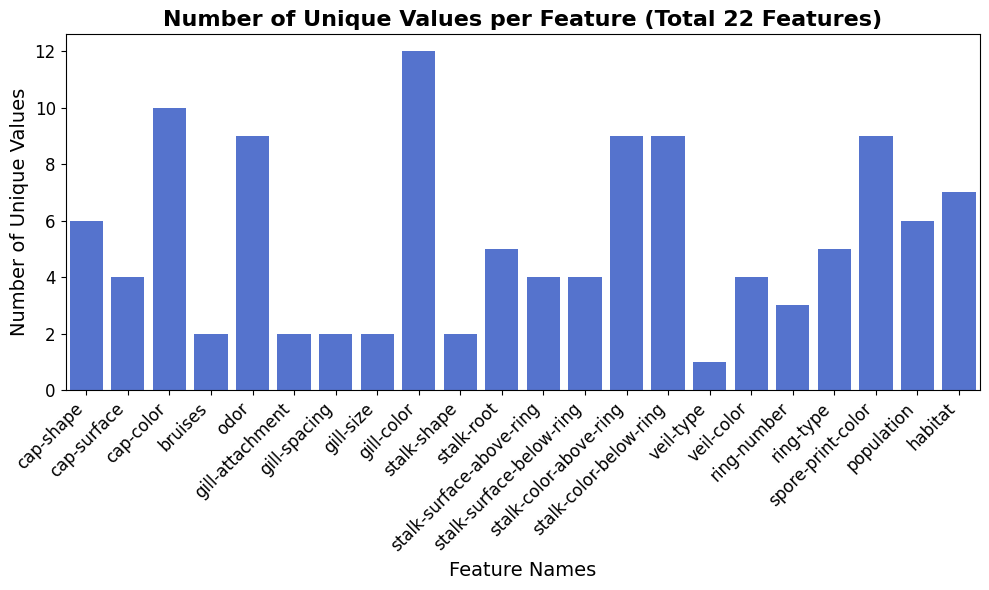

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Remove the target feature 'class'
df_features = df.drop(columns=['class'])

# Calculate the number of unique values for each feature
unique_counts = df_features.nunique()

# unique counts
plt.figure(figsize=(10, 6))

# Use a consistent color palette
sns.barplot(x=unique_counts.index, y=unique_counts.values, color='royalblue')

# Set plot labels and title
plt.title(f"Number of Unique Values per Feature (Total 22 Features)", fontsize=16, weight='bold')
plt.xlabel('Feature Names', fontsize=14)
plt.ylabel('Number of Unique Values', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)  # Rotate feature names for better readability
plt.yticks(fontsize=12)

# Clean up the layout
plt.tight_layout()

# Show the plot
plt.show()


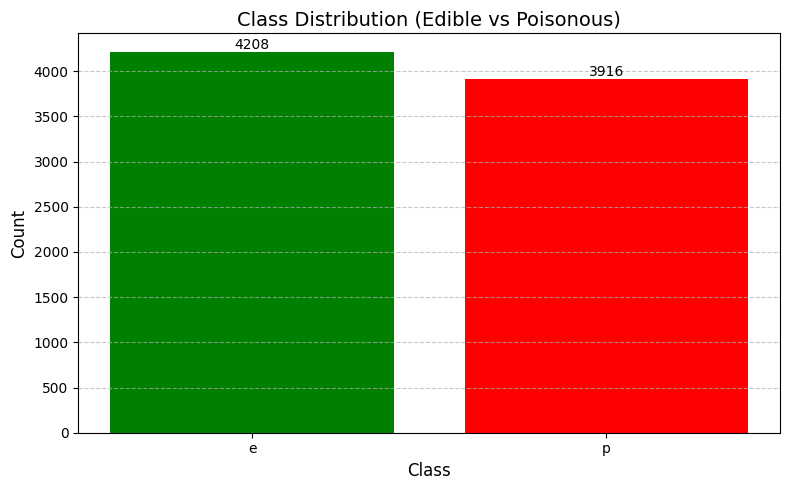

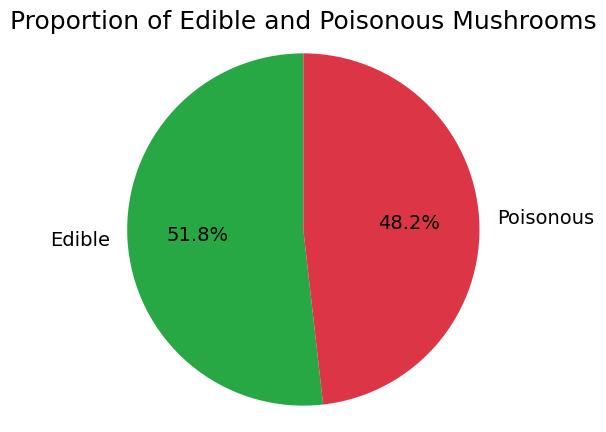

In [ ]:
value_counts = df['class'].value_counts()

colors = ['green' if cls == 'e' else 'red' for cls in value_counts.index]

plt.figure(figsize=(8, 5))
bars = plt.bar(value_counts.index, value_counts.values, color=colors)


for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height()}',
        ha='center', va='bottom', fontsize=10, color='black'
    )

plt.title('Class Distribution (Edible vs Poisonous)', fontsize=14)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

print("")


# piechart-

# Data
labels = ['Edible', 'Poisonous']
values = [df['class'].value_counts()['e'], df['class'].value_counts()['p']]
colors = ['#28a745', '#dc3545']

# Plot
plt.figure(figsize=(5, 5))
plt.pie(values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 14})
plt.title('Proportion of Edible and Poisonous Mushrooms', fontsize=18)
plt.axis('equal')
plt.show()


So the dataset is mostly balanced

In [ ]:
df['stalk-root'] = df['stalk-root'].replace('?', df['stalk-root'].mode()[0])

In [ ]:
df = df.drop('veil-type', axis=1)

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
encoder = LabelEncoder()

# Loop through all columns in the DataFrame
for col in df.columns:
    # Apply LabelEncoder to each column (encode labels)
    df[col] = encoder.fit_transform(df[col])


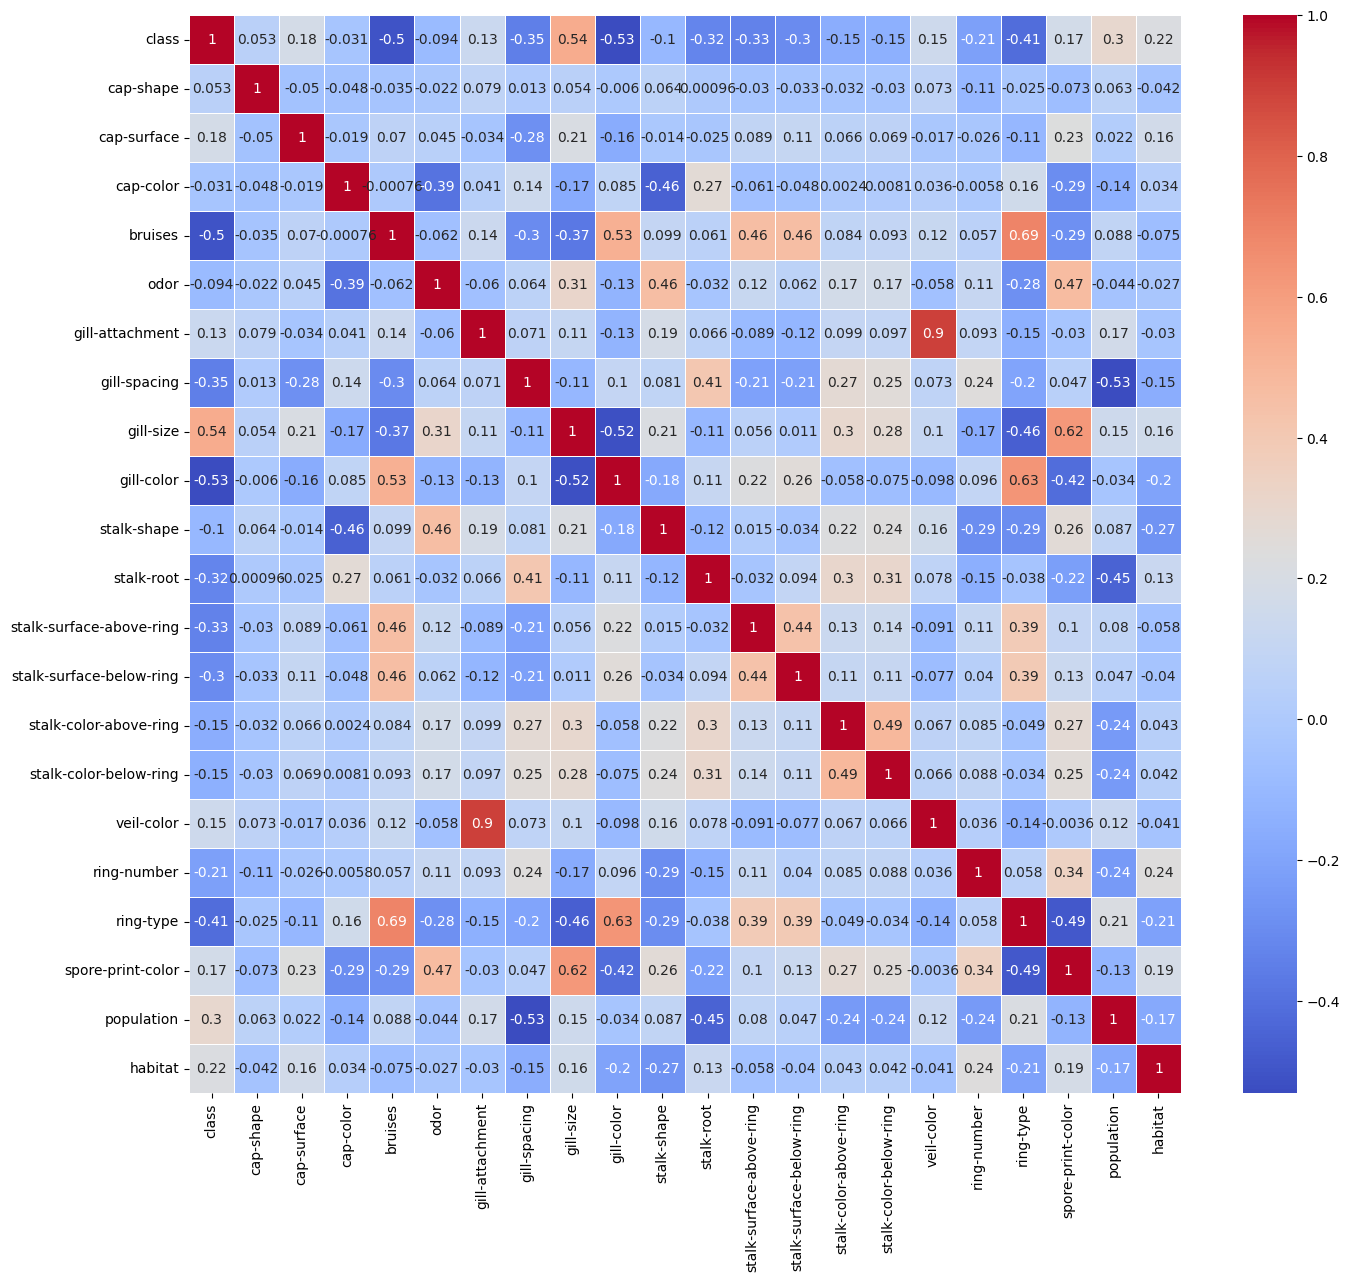

In [ ]:
plt.figure(figsize=(16,14))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', linewidths=0.6)
plt.show()

In [ ]:
df

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,6,1,0,1,4,...,2,2,7,7,2,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,...,2,2,7,7,2,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,...,2,2,7,7,2,1,4,3,2,3
3,1,5,3,8,1,6,1,0,1,5,...,2,2,7,7,2,1,4,2,3,5
4,0,5,2,3,0,5,1,1,0,4,...,2,2,7,7,2,1,0,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,0,3,2,4,0,5,0,0,0,11,...,2,2,5,5,1,1,4,0,1,2
8120,0,5,2,4,0,5,0,0,0,11,...,2,2,5,5,0,1,4,0,4,2
8121,0,2,2,4,0,5,0,0,0,5,...,2,2,5,5,1,1,4,0,1,2
8122,1,3,3,4,0,8,1,0,1,0,...,2,1,7,7,2,1,0,7,4,2


In [ ]:
X = df.drop("class", axis=1)
y = df["class"]

In [ ]:
X

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,5,2,4,1,6,1,0,1,4,0,...,2,2,7,7,2,1,4,2,3,5
1,5,2,9,1,0,1,0,0,4,0,...,2,2,7,7,2,1,4,3,2,1
2,0,2,8,1,3,1,0,0,5,0,...,2,2,7,7,2,1,4,3,2,3
3,5,3,8,1,6,1,0,1,5,0,...,2,2,7,7,2,1,4,2,3,5
4,5,2,3,0,5,1,1,0,4,1,...,2,2,7,7,2,1,0,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,3,2,4,0,5,0,0,0,11,0,...,2,2,5,5,1,1,4,0,1,2
8120,5,2,4,0,5,0,0,0,11,0,...,2,2,5,5,0,1,4,0,4,2
8121,2,2,4,0,5,0,0,0,5,0,...,2,2,5,5,1,1,4,0,1,2
8122,3,3,4,0,8,1,0,1,0,1,...,2,1,7,7,2,1,0,7,4,2


In [ ]:
y

,class
0,1
1,0
2,0
3,1
4,0
...,...
8119,0
8120,0
8121,0
8122,1


# **Train-Test Splitting**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (5686, 21)
y_train shape: (5686,)


In [ ]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (2438, 21)
y_test shape: (2438,)


# **ML MODELS**

# Naive Bayes Classifier

In [ ]:
# Naive Bayes Classifier
nb_classifier = GaussianNB()

# Fit the model
nb_classifier.fit(X_train, y_train)

# Make predictions
y_pred = nb_classifier.predict(X_test)
y_proba = nb_classifier.predict_proba(X_test)[:, 1]

Accuracy: 0.9044

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.91      0.91      1257
           1       0.91      0.90      0.90      1181

    accuracy                           0.90      2438
   macro avg       0.90      0.90      0.90      2438
weighted avg       0.90      0.90      0.90      2438


Confusion Matrix:
[[1146  111]
 [ 122 1059]]


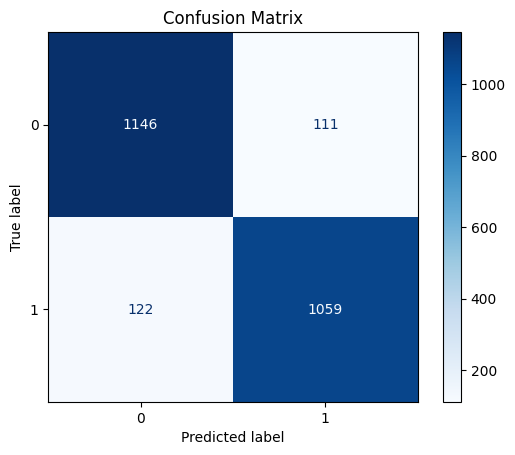

In [ ]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)

# Display Accuracy
print(f"Accuracy: {accuracy:.4f}\n")

# Display Classification Report
print("Classification Report:")
print(classification_rep)

# Display Confusion Matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred, labels=nb_classifier.classes_)
print(cm)

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nb_classifier.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

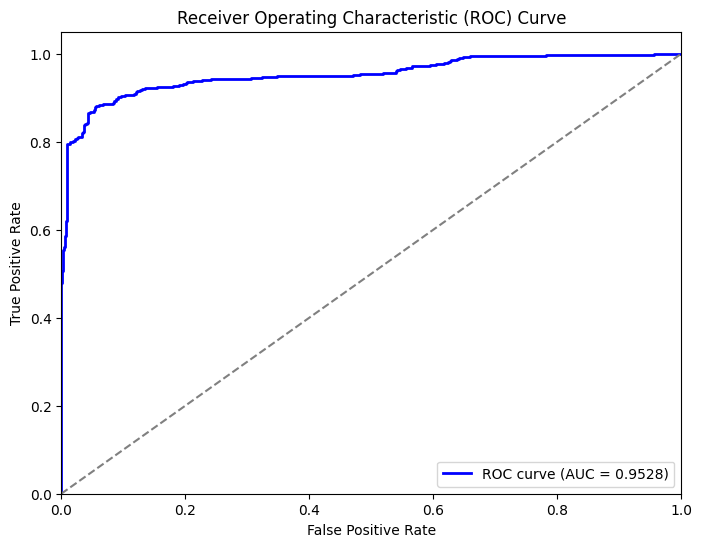

In [ ]:
# ROC AUC Calculation and Plot
fpr, tpr, thresholds = roc_curve(y_test, nb_classifier.predict_proba(X_test)[:, 1])
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# Decision Tree Classifier

In [ ]:
clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)

In [ ]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")

Accuracy: 0.9532

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95      1257
           1       0.93      0.97      0.95      1181

    accuracy                           0.95      2438
   macro avg       0.95      0.95      0.95      2438
weighted avg       0.95      0.95      0.95      2438


Confusion Matrix:
[[1173   84]
 [  30 1151]]


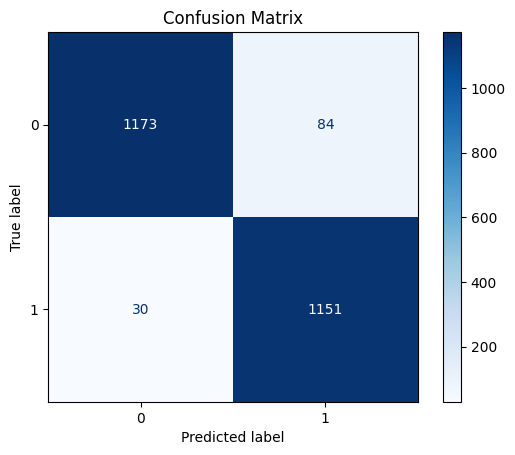

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Display Accuracy
print(f"Accuracy: {acc:.4f}\n")

# Display Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Display Confusion Matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
print(cm)

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()


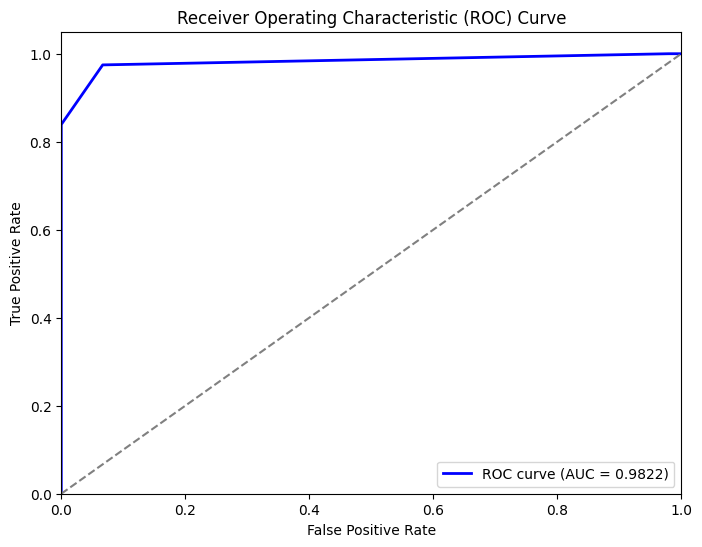

In [ ]:
from sklearn.metrics import roc_curve, auc

# ROC AUC Calculation and Plot
fpr, tpr, thresholds = roc_curve(y_test, clf.predict_proba(X_test)[:, 1])
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# ***Random Forest Classifier-***

Accuracy: 0.9893

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1257
           1       1.00      0.98      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438

AUC: 0.9998

Confusion Matrix:
[[1257    0]
 [  26 1155]]


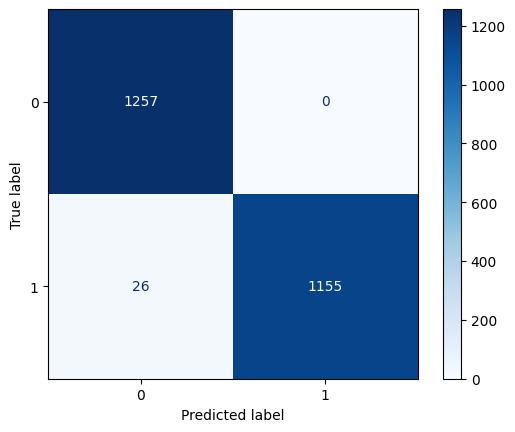

In [ ]:
# Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42, max_depth=5)
rf_classifier.fit(X_train, y_train)

# Make predictions
y_pred = rf_classifier.predict(X_test)
y_proba = rf_classifier.predict_proba(X_test)[:, 1]


# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)


# Display results
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"AUC: {auc_score:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)

# Confusion Matrix Display
ConfusionMatrixDisplay(conf_matrix, display_labels=rf_classifier.classes_).plot(cmap='Blues')
plt.show()

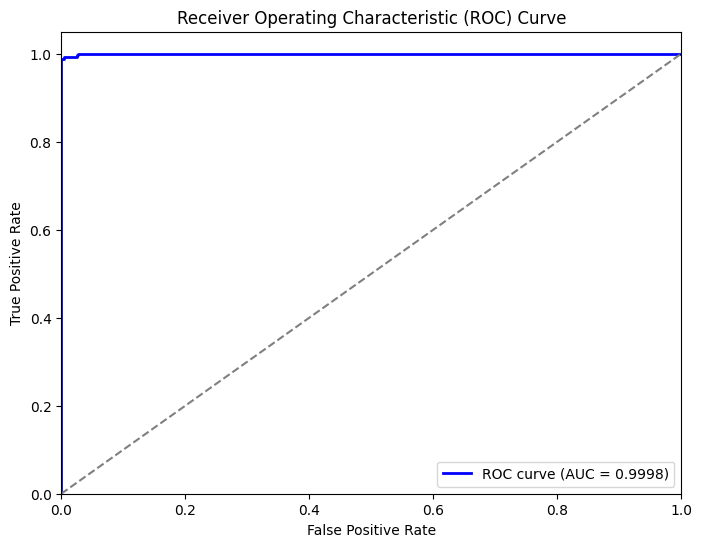

In [ ]:
# ROC AUC Calculation and Plot
fpr, tpr, thresholds = roc_curve(y_test, rf_classifier.predict_proba(X_test)[:, 1])
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# ***K-Nearest Neighbors Classifier-***

Accuracy: 0.9963

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      1257
           1       0.99      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

AUC: 1.0000

Confusion Matrix:
[[1249    8]
 [   1 1180]]


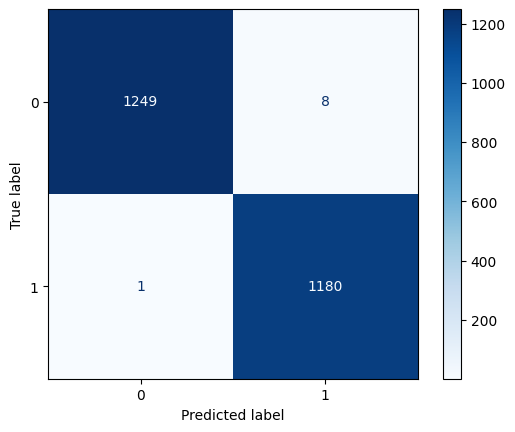

In [ ]:
# K-Nearest Neighbors Classifier
knn_classifier = KNeighborsClassifier()
knn_classifier.fit(X_train, y_train)

# Make predictions
y_pred = knn_classifier.predict(X_test)
y_proba = knn_classifier.predict_proba(X_test)[:, 1] # Get probabilities for the positive class


# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)


# Display results
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"AUC: {auc_score:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)

# Confusion Matrix Display
ConfusionMatrixDisplay(conf_matrix, display_labels=knn_classifier.classes_).plot(cmap='Blues')
plt.show()

# Standard Vector Machine - SVM Classifier

Accuracy : 0.9902

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1257
           1       1.00      0.98      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438

AUC: 0.9998

Confusion Matrix:
[[1254    3]
 [  21 1160]]


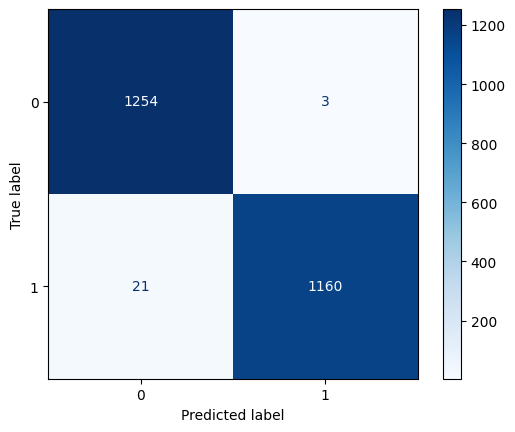

In [ ]:
from sklearn.metrics import roc_auc_score

# SVM Classifier
svm_classifier = SVC(random_state=42, probability=True) # probability=True is needed for predict_proba
svm_classifier.fit(X_train, y_train)

# Make predictions
y_pred = svm_classifier.predict(X_test)
y_proba = svm_classifier.predict_proba(X_test)[:, 1] # Get probabilities for the positive class


# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)


# Display results
print(f"Accuracy : {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"AUC: {auc_score:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)

# Confusion Matrix Display
ConfusionMatrixDisplay(conf_matrix, display_labels=svm_classifier.classes_).plot(cmap='Blues')
plt.show()

# Multilayer Perceptron (MLP) Classifier

Accuracy: 0.9992

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1257
           1       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

AUC: 1.0000

Confusion Matrix:
[[1257    0]
 [   2 1179]]


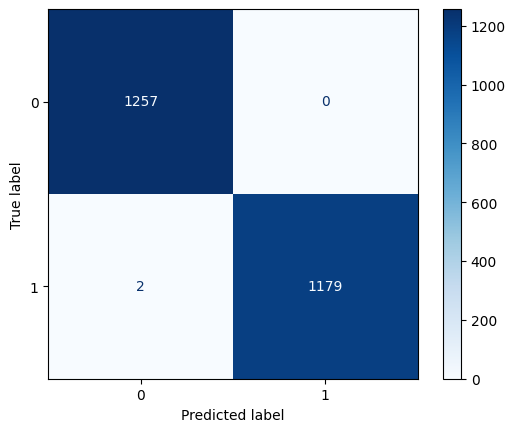

In [ ]:
# Multilayer Perceptron (MLP) Classifier
from sklearn.neural_network import MLPClassifier


mlp_classifier = MLPClassifier(hidden_layer_sizes=(10, 10), activation='relu', solver='adam', max_iter=500, random_state=42)
mlp_classifier.fit(X_train, y_train)

# Make predictions
y_pred = mlp_classifier.predict(X_test)

# For binary classification, get probabilities for positive class
if len(set(y_test)) == 2:
    y_proba = mlp_classifier.predict_proba(X_test)[:, 1]
else:
    y_proba = None

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(report)

if y_proba is not None:
    auc_score = roc_auc_score(y_test, y_proba)
    print(f"AUC: {auc_score:.4f}")

print("\nConfusion Matrix:")
print(conf_matrix)

# Display Confusion Matrix
ConfusionMatrixDisplay(conf_matrix, display_labels=mlp_classifier.classes_).plot(cmap='Blues')
plt.show()


# **Summary**

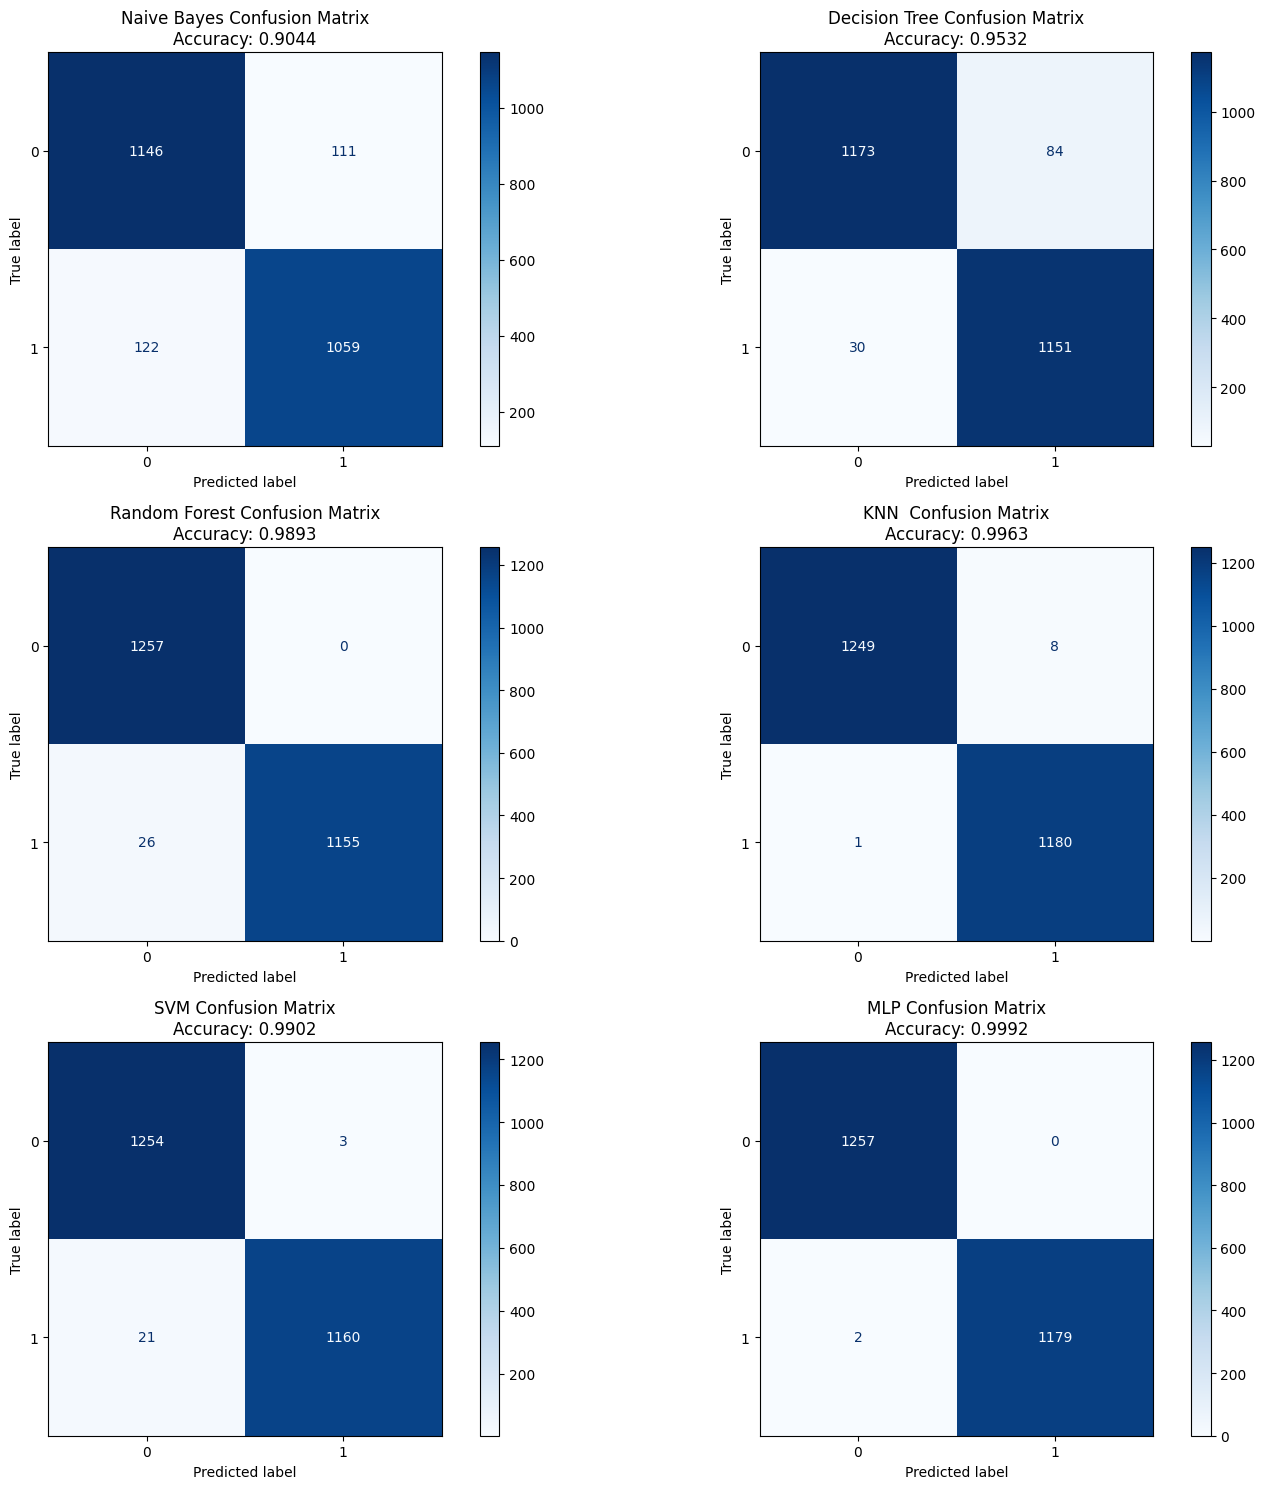

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Create a figure with subplots for each model's confusion matrix
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 15))
axes = axes.flatten() # Flatten the 2D array of axes for easier iteration

# Regenerate predictions for each model
y_pred_nb = nb_classifier.predict(X_test)
y_pred_dt = clf.predict(X_test)
y_pred_rf = rf_classifier.predict(X_test)
y_pred_knn = knn_classifier.predict(X_test)
y_pred_svm = svm_classifier.predict(X_test)
y_pred_mlp = mlp_classifier.predict(X_test)


# List of models and their corresponding predicted values
models = [
    (nb_classifier, "Naive Bayes", y_pred_nb),
    (clf, "Decision Tree", y_pred_dt),
    (rf_classifier, "Random Forest", y_pred_rf),
    (knn_classifier, "KNN ", y_pred_knn),
    (svm_classifier, "SVM", y_pred_svm),
    (mlp_classifier, "MLP", y_pred_mlp)
]


# Plot Confusion Matrices in subplots
for i, (model, model_name, y_pred_model) in enumerate(models):
    if i < len(axes): # Ensure we don't go out of bounds for axes
        ax = axes[i]
        cm = confusion_matrix(y_test, y_pred_model, labels=model.classes_)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
        disp.plot(cmap='Blues', ax=ax)
        acc = accuracy_score(y_test, y_pred_model)
        ax.set_title(f'{model_name} Confusion Matrix\nAccuracy: {acc:.4f}')

# Hide any unused subplots
for j in range(len(models), len(axes)):
    if j < len(axes): # Ensure we don't go out of bounds for axes
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
# Dictionary to store classification reports
classification_reports = {}

# Get classification report for each model
classification_reports['Naive Bayes'] = classification_report(y_test, nb_classifier.predict(X_test), output_dict=True)
classification_reports['Decision Tree'] = classification_report(y_test, clf.predict(X_test), output_dict=True)
classification_reports['Random Forest'] = classification_report(y_test, rf_classifier.predict(X_test), output_dict=True)
classification_reports['KNN'] = classification_report(y_test, knn_classifier.predict(X_test), output_dict=True)
classification_reports['SVM'] = classification_report(y_test, svm_classifier.predict(X_test), output_dict=True)
classification_reports['MLP'] = classification_report(y_test, mlp_classifier.predict(X_test), output_dict=True)

# Convert the dictionary to a pandas DataFrame for better visualization
# We will focus on the metrics for class 0, class 1, accuracy, macro avg, and weighted avg
metrics_data = {}
for model_name, report_dict in classification_reports.items():
    metrics_data[model_name] = {
        'Precision (Class 0)': report_dict['0']['precision'],
        'Recall (Class 0)': report_dict['0']['recall'],
        'F1-score (Class 0)': report_dict['0']['f1-score'],
        'Support (Class 0)': report_dict['0']['support'],
        'Precision (Class 1)': report_dict['1']['precision'],
        'Recall (Class 1)': report_dict['1']['recall'],
        'F1-score (Class 1)': report_dict['1']['f1-score'],
        'Support (Class 1)': report_dict['1']['support'],
        'Accuracy': report_dict['accuracy'],
        'Macro Avg Precision': report_dict['macro avg']['precision'],
        'Macro Avg Recall': report_dict['macro avg']['recall'],
        'Macro Avg F1-score': report_dict['macro avg']['f1-score'],
        'Weighted Avg Precision': report_dict['weighted avg']['precision'],
        'Weighted Avg Recall': report_dict['weighted avg']['recall'],
        'Weighted Avg F1-score': report_dict['weighted avg']['f1-score']
    }

metrics_df = pd.DataFrame.from_dict(metrics_data, orient='index')

# Display the comparison table
print("Classification Report Metrics Comparison:")
display(metrics_df)

Classification Report Metrics Comparison:


,Precision (Class 0),Recall (Class 0),F1-score (Class 0),Support (Class 0),Precision (Class 1),Recall (Class 1),F1-score (Class 1),Support (Class 1),Accuracy,Macro Avg Precision,Macro Avg Recall,Macro Avg F1-score,Weighted Avg Precision,Weighted Avg Recall,Weighted Avg F1-score
Naive Bayes,0.903785,0.911695,0.907723,1257.0,0.905128,0.896698,0.900893,1181.0,0.904430,0.904457,0.904196,0.904308,0.904436,0.904430,0.904414
Decision Tree,0.975062,0.933174,0.953659,1257.0,0.931984,0.974598,0.952815,1181.0,0.953240,0.953523,0.953886,0.953237,0.954195,0.953240,0.953250
Random Forest,0.979735,1.000000,0.989764,1257.0,1.000000,0.977985,0.988870,1181.0,0.989336,0.989867,0.988992,0.989317,0.989552,0.989336,0.989331
KNN,0.999200,0.993636,0.996410,1257.0,0.993266,0.999153,0.996201,1181.0,0.996308,0.996233,0.996394,0.996305,0.996325,0.996308,0.996309
SVM,0.983529,0.997613,0.990521,1257.0,0.997420,0.982218,0.989761,1181.0,0.990156,0.990475,0.989916,0.990141,0.990258,0.990156,0.990153
MLP,0.998411,1.000000,0.999205,1257.0,1.000000,0.998307,0.999153,1181.0,0.999180,0.999206,0.999153,0.999179,0.999181,0.999180,0.999180


In [ ]:
# Dictionary to store AUC scores
auc_scores = {}

# Calculate AUC for each model
auc_scores['Naive Bayes'] = roc_auc_score(y_test, nb_classifier.predict_proba(X_test)[:, 1])
auc_scores['Decision Tree'] = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
auc_scores['Random Forest'] = roc_auc_score(y_test, rf_classifier.predict_proba(X_test)[:, 1])
auc_scores['KNN'] = roc_auc_score(y_test, knn_classifier.predict_proba(X_test)[:, 1])
auc_scores['SVM'] = roc_auc_score(y_test, svm_classifier.predict_proba(X_test)[:, 1])
auc_scores['MLP'] = roc_auc_score(y_test, mlp_classifier.predict_proba(X_test)[:, 1])


# Create a pandas DataFrame from the dictionary for a table format
auc_df = pd.DataFrame.from_dict(auc_scores, orient='index', columns=['AUC Score'])

# Sort the DataFrame by AUC score in descending order
auc_df = auc_df.sort_values(by='AUC Score', ascending=False)

# Display the AUC scores table
print("AUC Scores Comparison Table:")
display(auc_df)

AUC Scores Comparison Table:


,AUC Score
MLP,1.000000
KNN,0.999973
SVM,0.999807
Random Forest,0.999775
Decision Tree,0.982176
Naive Bayes,0.952829
